# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1

ct = ct.sort_values(["z", "y", "x"]).reset_index(drop=True)

vol = ct.intensity_hu.values.reshape(NZ, NY, NX)
labels = ct.label.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [6]:

# TODO 1: Number of voxels and storage size
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 2 / 1_000_000

# TODO 2: Physical extent and voxel volume
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3: Rendering samples
samples_per_frame = 512 * 300 * 512
samples_video = samples_per_frame * 120

# TODO 4: Early ray termination
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")


78,643,200 voxels = 157.3 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_Ignoring anisotropic voxel spacing would cause two main problems. First, anatomical structures would appear stretched or compressed in the coronal and sagittal views because the voxel dimensions differ along the three axes. Second, physical measurements such as distances, lengths and shapes would be inaccurate because the software would treat unequal voxel dimensions as equal. Applying the correct voxel aspect ratio preserves anatomical proportions and supports reliable radiological interpretation.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

Lesion centroid (z, y, x): (28, 40, 41)


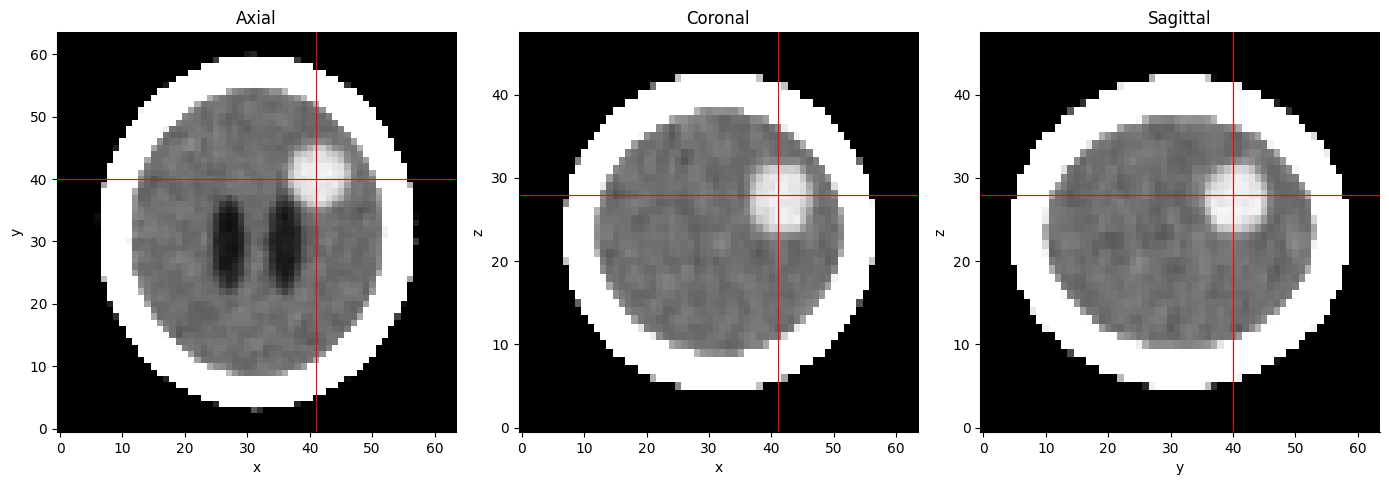

Ground-truth centroid (z, y, x): [27.5 40.5 41.5]
Centroid distance from ground truth: 2.92 mm


In [7]:

def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1: Find candidate voxels inside the brain
bone = vol > 300
inside = ndimage.binary_fill_holes(bone) & ~bone
inside = ndimage.binary_erosion(inside, iterations=3)

candidates = (vol > 55) & (vol < 90) & inside

# TODO 2: Keep the largest connected component
components, n_components = ndimage.label(candidates)

if n_components == 0:
    raise ValueError("No lesion candidates found. Check the volume and mask.")

sizes = np.bincount(components.ravel())
sizes[0] = 0
largest = np.argmax(sizes)

lesion = components == largest

cz, cy, cx = ndimage.center_of_mass(lesion)
cz, cy, cx = int(round(cz)), int(round(cy)), int(round(cx))

print(f"Lesion centroid (z, y, x): ({cz}, {cy}, {cx})")

# TODO 3: Display axial, coronal and sagittal slices
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

# Axial: fixed z
axes[0].imshow(window(vol[cz, :, :], 80, 40),
               cmap="gray", origin="lower", aspect="equal")
axes[0].axhline(cy, color="red", linewidth=0.8)
axes[0].axvline(cx, color="red", linewidth=0.8)
axes[0].set_title("Axial")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")

# Coronal: fixed y
axes[1].imshow(window(vol[:, cy, :], 80, 40),
               cmap="gray", origin="lower", aspect=ASPECT)
axes[1].axhline(cz, color="red", linewidth=0.8)
axes[1].axvline(cx, color="red", linewidth=0.8)
axes[1].set_title("Coronal")
axes[1].set_xlabel("x")
axes[1].set_ylabel("z")

# Sagittal: fixed x
axes[2].imshow(window(vol[:, :, cx], 80, 40),
               cmap="gray", origin="lower", aspect=ASPECT)
axes[2].axhline(cz, color="red", linewidth=0.8)
axes[2].axvline(cy, color="red", linewidth=0.8)
axes[2].set_title("Sagittal")
axes[2].set_xlabel("y")
axes[2].set_ylabel("z")

plt.tight_layout()
plt.show()

# TODO 4: Evaluation only — compare with ground truth
true_centroid = np.array(ndimage.center_of_mass(labels == 5))
estimated_centroid = np.array([cz, cy, cx])

distance_mm = np.linalg.norm(
    (estimated_centroid - true_centroid) * np.array(SPACING)
)

print(f"Ground-truth centroid (z, y, x): {true_centroid}")
print(f"Centroid distance from ground truth: {distance_mm:.2f} mm")


**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_The erosion step removes voxels near the inner skull boundary, where the partial-volume effect causes a voxel to contain a mixture of bone and soft tissue. These voxels can have intermediate intensity values that overlap with the tumour's intensity range, producing false-positive candidates. Erosion reduces these boundary voxels and helps isolate the lesion. However, excessive erosion may remove genuine lesion voxels, so the number of erosion iterations must balance reducing false positives against preserving the lesion.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,Threshold (HU),Voxels,Volume (mL),Dice Score
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


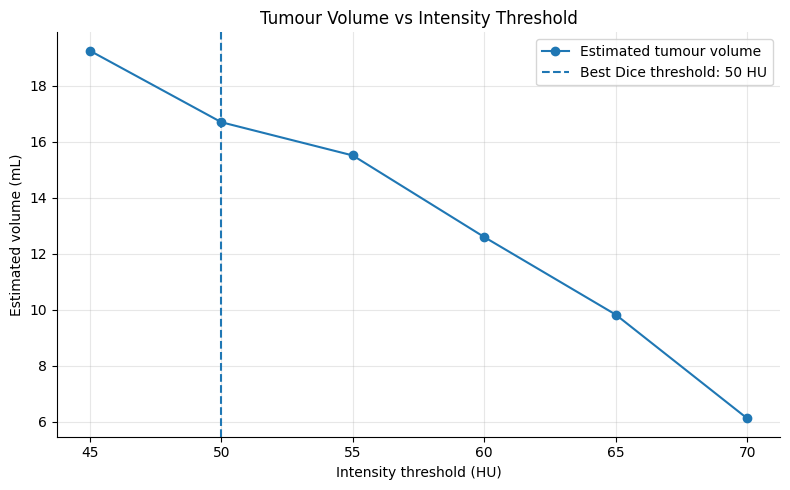

Estimated volume range: 6.120–19.260 mL
Best Dice score: 0.9935
Threshold with best Dice: 50 HU


In [8]:

truth = labels == 5
rows = []

thresholds = [45, 50, 55, 60, 65, 70]

for c in thresholds:
    # Segment voxels above the current intensity threshold
    mask = vol > c

    # Find connected components
    components, n_components = ndimage.label(mask)

    # Select the component containing the estimated lesion centre
    seed_label = components[cz, cy, cx]

    if seed_label == 0:
        voxel_count = 0
        volume_ml = 0.0
        dice = 0.0
    else:
        region = components == seed_label

        voxel_count = int(np.count_nonzero(region))
        volume_ml = voxel_count * VOXEL_MM3 / 1000.0

        intersection = np.count_nonzero(region & truth)
        denominator = voxel_count + np.count_nonzero(truth)

        dice = (2.0 * intersection / denominator) if denominator else 0.0

    rows.append({
        "Threshold (HU)": c,
        "Voxels": voxel_count,
        "Volume (mL)": volume_ml,
        "Dice Score": dice
    })

# Display results
table = pd.DataFrame(rows)
display(table)

# Plot volume against threshold
best_idx = table["Dice Score"].idxmax()
best_threshold = table.loc[best_idx, "Threshold (HU)"]

plt.figure(figsize=(8, 5))
plt.plot(
    table["Threshold (HU)"],
    table["Volume (mL)"],
    marker="o",
    label="Estimated tumour volume"
)
plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best Dice threshold: {best_threshold} HU"
)
plt.xlabel("Intensity threshold (HU)")
plt.ylabel("Estimated volume (mL)")
plt.title("Tumour Volume vs Intensity Threshold")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Report volume range
min_volume = table["Volume (mL)"].min()
max_volume = table["Volume (mL)"].max()

print(f"Estimated volume range: {min_volume:.3f}–{max_volume:.3f} mL")
print(f"Best Dice score: {table.loc[best_idx, 'Dice Score']:.4f}")
print(f"Threshold with best Dice: {best_threshold} HU")


**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_I would choose an intensity threshold by considering both the Dice score and the anatomical plausibility of the segmented tumour. A higher Dice score indicates better overlap with the reference segmentation, but the result should also be checked visually to ensure that surrounding structures are not incorrectly included. The estimated volume may change considerably with small threshold adjustments, so I would report a plausible volume range rather than relying only on one value. Visual overlays of the segmentations at different thresholds would help communicate this uncertainty to the clinical team.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

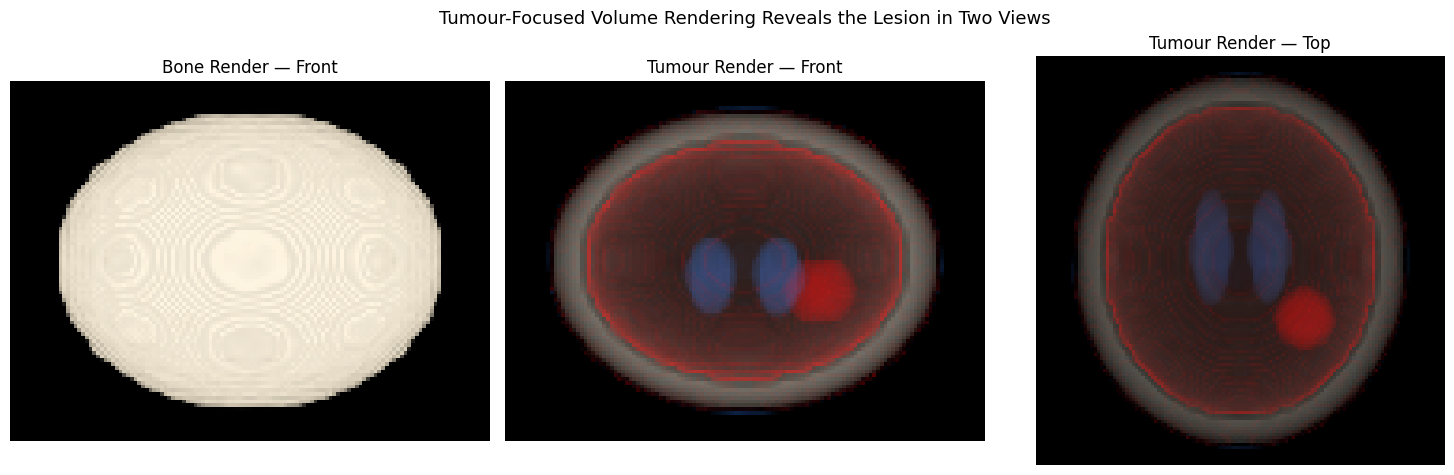

In [11]:

# TODO 1: Bone transfer function
bone_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),
    (200, (0, 0, 0), 0.0),
    (400, (1, 0.95, 0.85), 0.3),
    (1500, (1, 1, 1), 0.6)
])

# TODO 2: Tumour transfer function
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),
    (4, (0, 0, 0), 0.0),
    (5, (0.2, 0.5, 1.0), 0.01),
    (20, (0.2, 0.5, 1.0), 0.02),
    (30, (0, 0, 0), 0.0),
    (45, (0, 0, 0), 0.0),
    (55, (1, 0, 0), 0.03),
    (90, (1, 0, 0), 0.04),
    (120, (0, 0, 0), 0.0),
    (200, (0, 0, 0), 0.0),
    (300, (0.8, 0.7, 0.6), 0.005),
    (400, (1, 0.95, 0.85), 0.01),
    (1500, (1, 1, 1), 0.01)
])

# TODO 1 & 3: Render RGB images (render returns RGB and opacity)
bone_img, bone_opacity = render(vol, bone_tf, axis=1)
front_img, front_opacity = render(vol, tumour_tf, axis=1)
top_img, top_opacity = render(vol, tumour_tf, axis=0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

axes[0].imshow(bone_img)
axes[0].set_title("Bone Render — Front")

axes[1].imshow(front_img)
axes[1].set_title("Tumour Render — Front")

axes[2].imshow(top_img)
axes[2].set_title("Tumour Render — Top")

for ax in axes:
    ax.axis("off")

# TODO 4: Conclusion-style title
fig.suptitle(
    "Tumour-Focused Volume Rendering Reveals the Lesion in Two Views",
    fontsize=13
)

plt.tight_layout()
plt.show()


**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_The faint red rim may result from overlapping intensity ranges and partial-volume voxels near the skull boundary. These voxels can receive colours and opacity values intended for the tumour, creating an unwanted boundary artefact. A possible remedy is to use spatial masking or clipping to exclude the skull-boundary region from tumour rendering. A transfer function alone maps intensity values to colour and opacity; it cannot distinguish two tissues that have similar intensity values based on their spatial location.


## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_The suspected tumour was identified using intensity-based segmentation and examined in axial, coronal, and sagittal views. Its estimated volume should be reported as a range based on the minimum and maximum volumes obtained across the tested intensity thresholds in Task 3, rather than as a single exact measurement. I recommend using a segmentation overlay on the multiplanar reconstruction (MPR) views because it allows the clinical team to assess the lesion's location and boundaries in three anatomical planes. The 3D volume rendering provides useful spatial context for understanding the relationship between the tumour and surrounding structures, including the ventricles. However, the rendering depends on the chosen transfer function and intensity thresholds, so faint structures or overlapping tissue intensities may be misleading. The estimated volume and boundaries should therefore be reviewed alongside the original CT slices before clinical decisions are made.